# Chart examples for the group presentation

A menu of charts for presentation #2, drawn from our real data with **plotnine** (the course plotting
library). Each chart has a note on what it shows and when to use it. Pick the ones that tell our story;
5–6 is plenty for a short talk.

Slide settings used throughout: wide 16:9 shape, large fonts (`base_size=14`), bold titles, one message
per chart in the title. Every chart is also saved as a PNG in `output/figures/presentation_examples/`,
ready to drag into slides.

| # | Chart | Answers |
|---|---|---|
| 1 | Map: share of elderly | Where are the elderly concentrated? |
| 2 | Map: distance to hospital | Where is access weakest? |
| 3 | Bar: high-elderly subzones by region | Is clustering regional? |
| 4 | Histogram weighted by elderly | How far does the typical elderly person live? |
| 5 | 100% stacked bar: distance bands by region | Which regions have more elderly far away? |
| 6 | Dodged bar: any vs public hospital | What if the elderly need an affordable (public) hospital? |
| 7 | Boxplot + points: distance by region | How much do subzones vary within each region? |
| 8 | Scatter + trend line | Does more elderly mean worse access? |
| 9 | Correlation heatmap | All Spearman correlations at a glance |
| 10 | Coefficient plot (OLS) | Regression results without a big table |
| 11 | Predicted probability by region (logit) | Chance of being far from a hospital, by region |
| 12 | Lollipop: priority subzones | Which places should policy look at first? |

In [1]:
import warnings
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import plotnine as p9
import statsmodels.formula.api as smf
from marginaleffects import datagrid, predictions
from scipy import stats

warnings.filterwarnings("ignore")

RAW = Path("data/raw")
OUT = Path("output/figures/presentation_examples")
OUT.mkdir(parents=True, exist_ok=True)

REGIONS = ["Central", "East", "North", "North-East", "West"]
REGION_COLOURS = dict(zip(REGIONS, ["#4C72B0", "#55A868", "#8172B2", "#CCB974", "#C44E52"]))

df = pd.read_csv("data/processed/subzone_elderly_access.csv")
df["region"] = pd.Categorical(df.REGION_N.str.replace(" REGION", "").str.title(), categories=REGIONS)

# One slide theme, reused by every chart
SLIDE = p9.theme_minimal(base_size=14) + p9.theme(
    figure_size=(10, 5.6),
    plot_title=p9.element_text(weight="bold", size=18),
    plot_subtitle=p9.element_text(size=12, color="#555555"),
    panel_grid_minor=p9.element_blank(),
)


def save(plot, name):
    plot.save(OUT / f"{name}.png", dpi=150, verbose=False)
    return plot

## 1. Map: where the elderly live

**Shows:** share of residents aged 65+ in each subzone, with acute hospitals on top.
**Use it:** as the opening chart, to introduce the geography. Grey = subzones with too few residents.

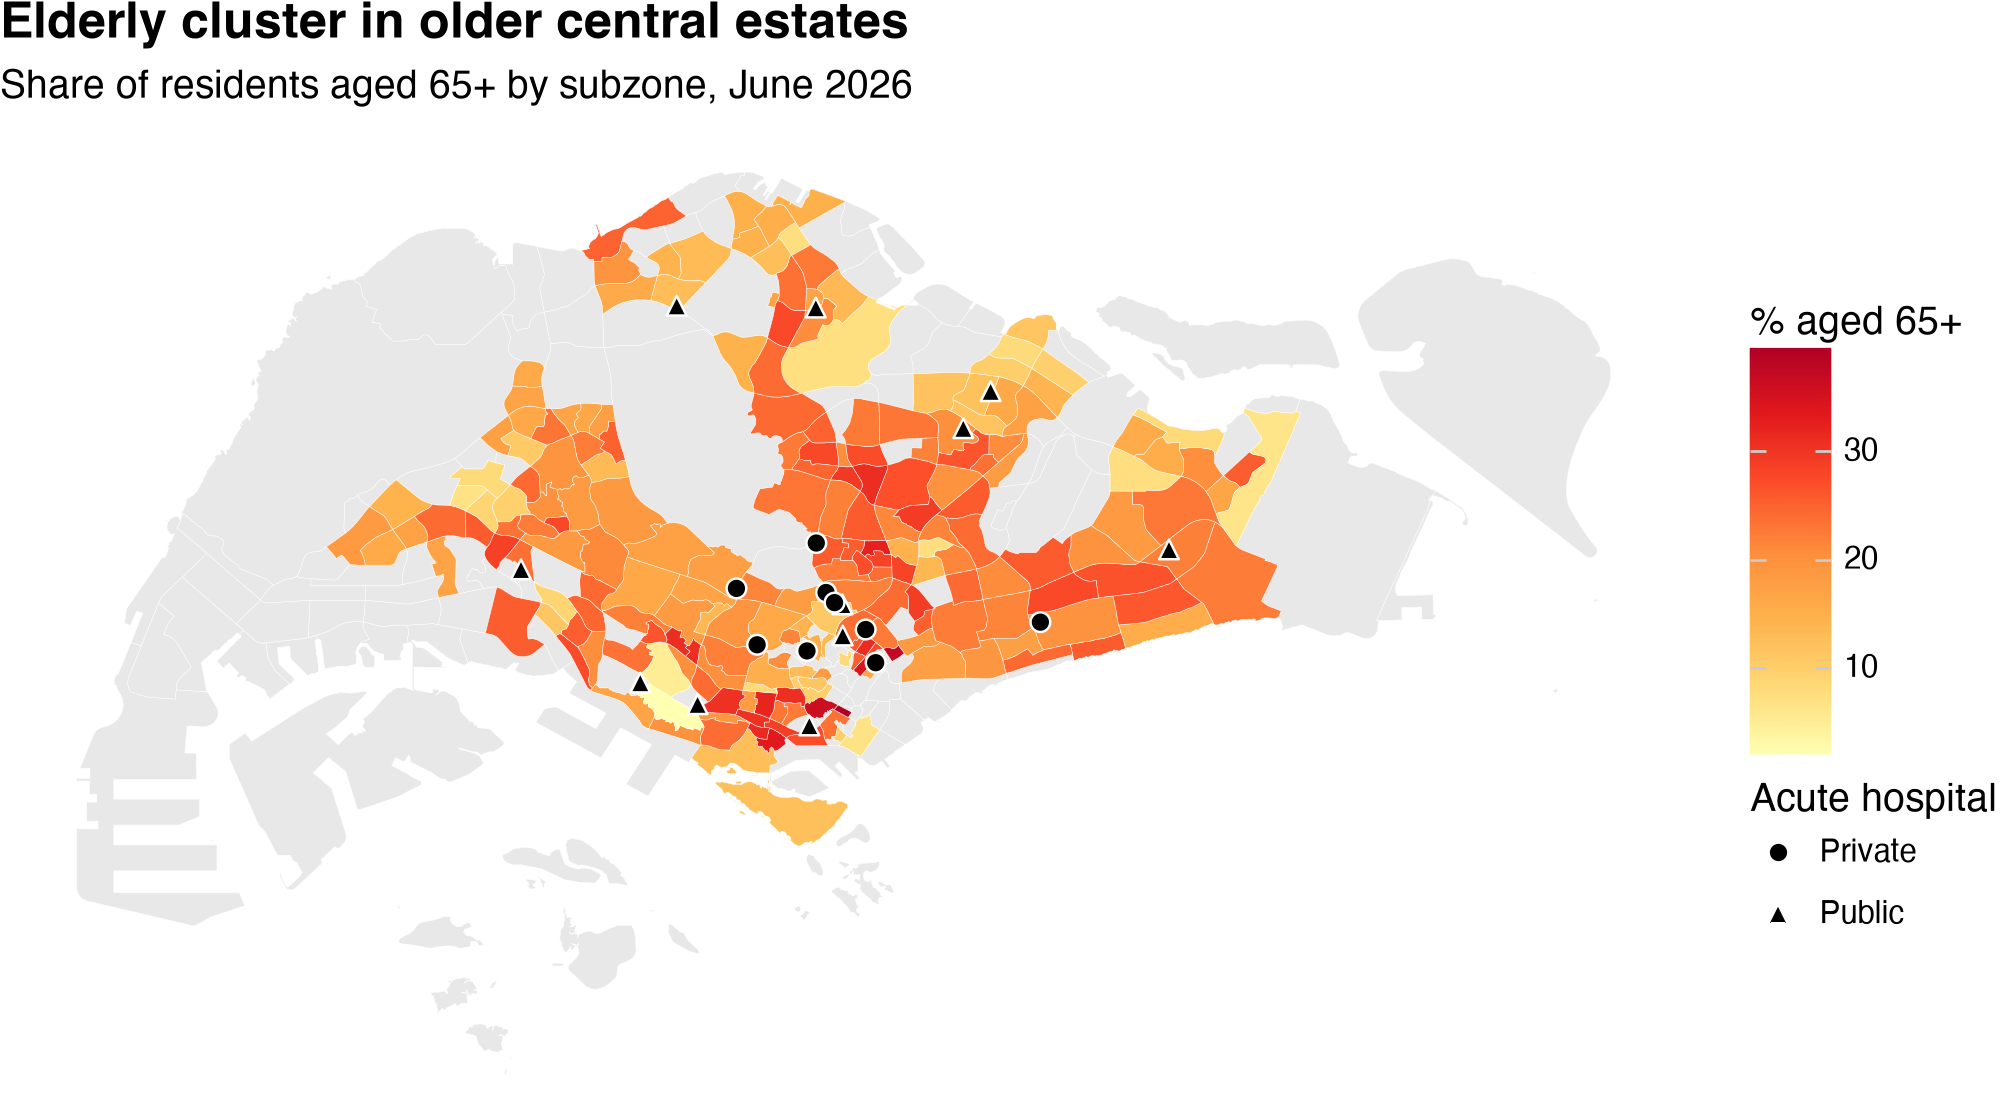

In [2]:
subzones = gpd.read_file(RAW / "mp2019_subzone_no_sea.geojson")
subzones["key"] = subzones.PLN_AREA_N + "|" + subzones.SUBZONE_N
geo = subzones.merge(df.drop(columns="geometry", errors="ignore"), on="key", how="left")

hospitals = gpd.read_file(RAW / "oex" / "oex_sgp_acute_hospitals_osm.geojson").merge(
    pd.read_csv(RAW / "moh_acute_hospitals.csv"), left_on="id", right_on="osm_id")
hospitals["geometry"] = hospitals.to_crs(3414).representative_point().to_crs(4326)
hospitals["x"], hospitals["y"] = hospitals.geometry.x, hospitals.geometry.y


def slide_map(column, title, subtitle, fill_label, palette):
    return (
        p9.ggplot()
        + p9.geom_map(geo[geo[column].isna()], fill="#e8e8e8", color="white", size=0.1)
        + p9.geom_map(geo[geo[column].notna()], p9.aes(fill=column), color="white", size=0.1)
        + p9.geom_point(hospitals, p9.aes("x", "y", shape="sector"), size=3.5, fill="black", color="white")
        + p9.scale_fill_distiller(palette=palette, direction=1)
        + p9.labs(title=title, subtitle=subtitle, fill=fill_label, shape="Acute hospital")
        + p9.theme_void(base_size=14)
        + p9.theme(figure_size=(10, 5.6), plot_title=p9.element_text(weight="bold", size=18))
    )


save(slide_map("pct65", "Elderly cluster in older central estates",
               "Share of residents aged 65+ by subzone, June 2026", "% aged 65+", "YlOrRd"), "01_map_elderly_share")

## 2. Map: distance to the nearest acute hospital

**Shows:** average straight-line distance from elderly homes to the nearest acute hospital.
**Use it:** next to chart 1 (same layout) so the audience can compare "where elderly are" with
"where access is weak".

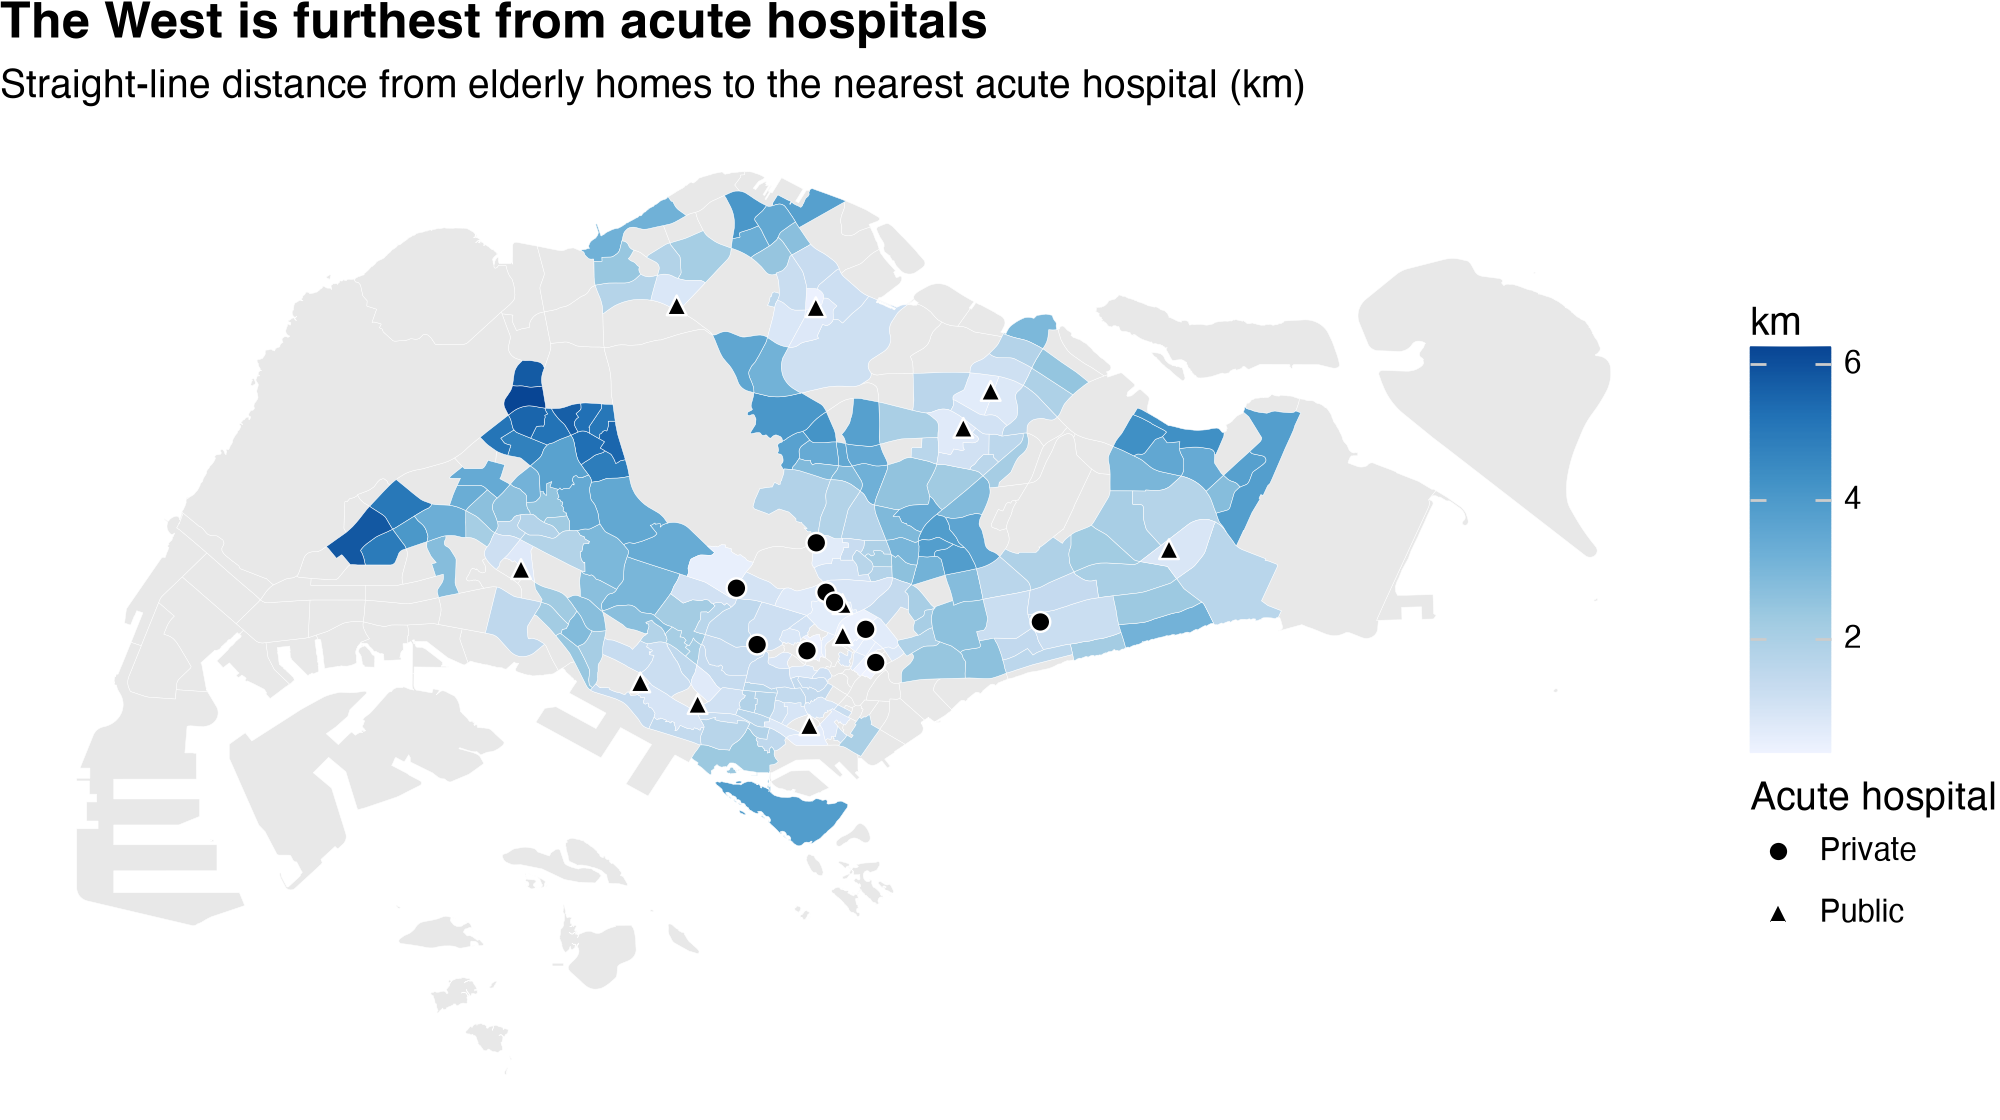

In [3]:
save(slide_map("dist_km_any", "The West is furthest from acute hospitals",
               "Straight-line distance from elderly homes to the nearest acute hospital (km)", "km", "Blues"),
     "02_map_distance")

## 3. Bar chart: high-elderly subzones by region

**Shows:** % of each region's subzones that are in the top quarter for elderly share (the chi-square test).
**Use it:** to summarise the clustering result with one number per region. Put the test result in the
subtitle so the audience knows the difference is not significant.

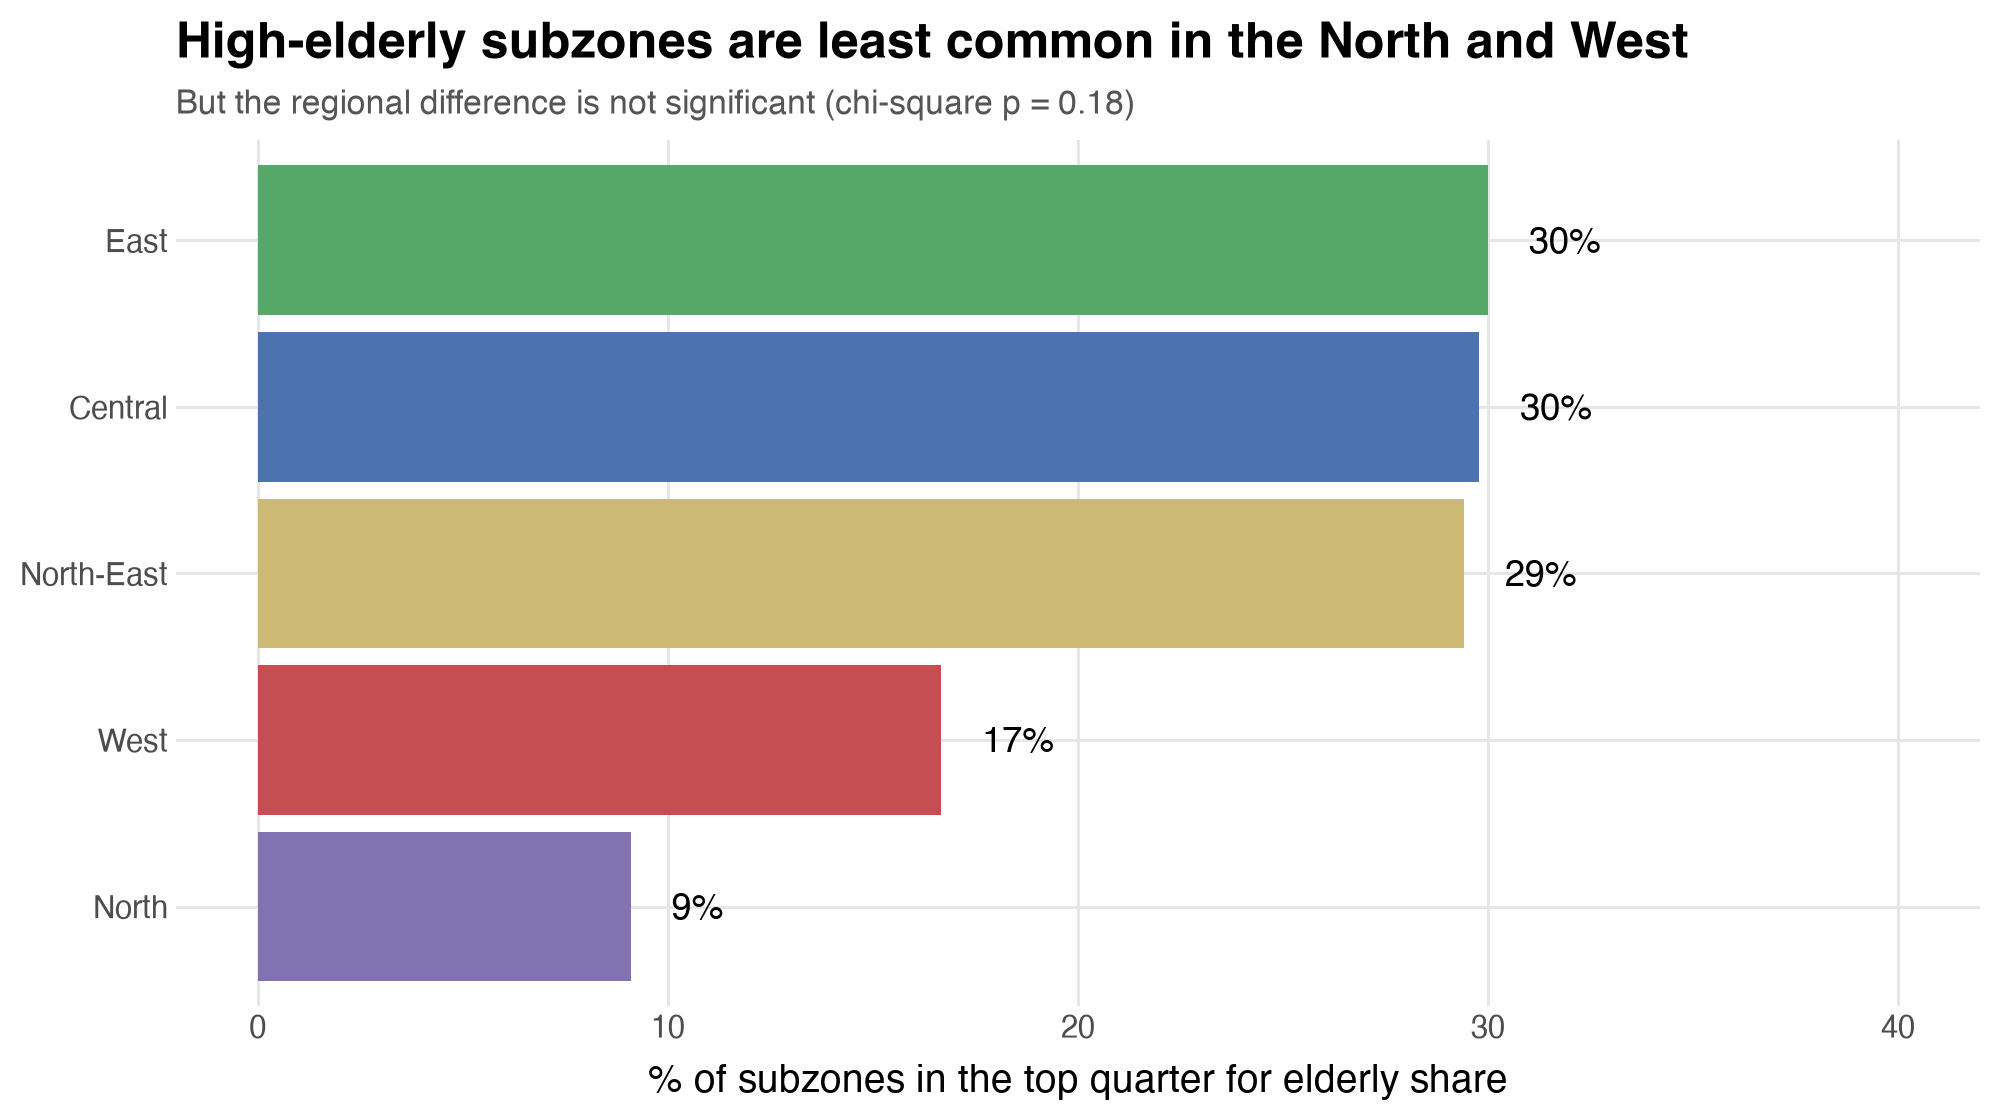

In [4]:
df["high_elderly"] = df.pct65 >= df.pct65.quantile(0.75)
by_region = df.groupby("region", observed=True).high_elderly.mean().mul(100).reset_index(name="pct")
chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df.region, df.high_elderly))
save(
    p9.ggplot(by_region, p9.aes("reorder(region, pct)", "pct", fill="region"))
    + p9.geom_col(show_legend=False)
    + p9.geom_text(p9.aes(label="pct.round(0).astype(int).astype(str) + '%'"), ha="left", nudge_y=1, size=13)
    + p9.coord_flip()
    + p9.scale_fill_manual(REGION_COLOURS)
    + p9.scale_y_continuous(limits=(0, 40))
    + p9.labs(x="", y="% of subzones in the top quarter for elderly share",
              title="High-elderly subzones are least common in the North and West",
              subtitle=f"But the regional difference is not significant (chi-square p = {p:.2f})")
    + SLIDE,
    "03_bar_high_elderly_by_region",
)

## 4. Histogram weighted by elderly

**Shows:** how many elderly (not subzones) live at each distance. `weight="pop65"` makes each subzone count
by its number of elderly. The dashed line is the median elderly person.
**Use it:** for the headline "most elderly live within ~2 km of an acute hospital".

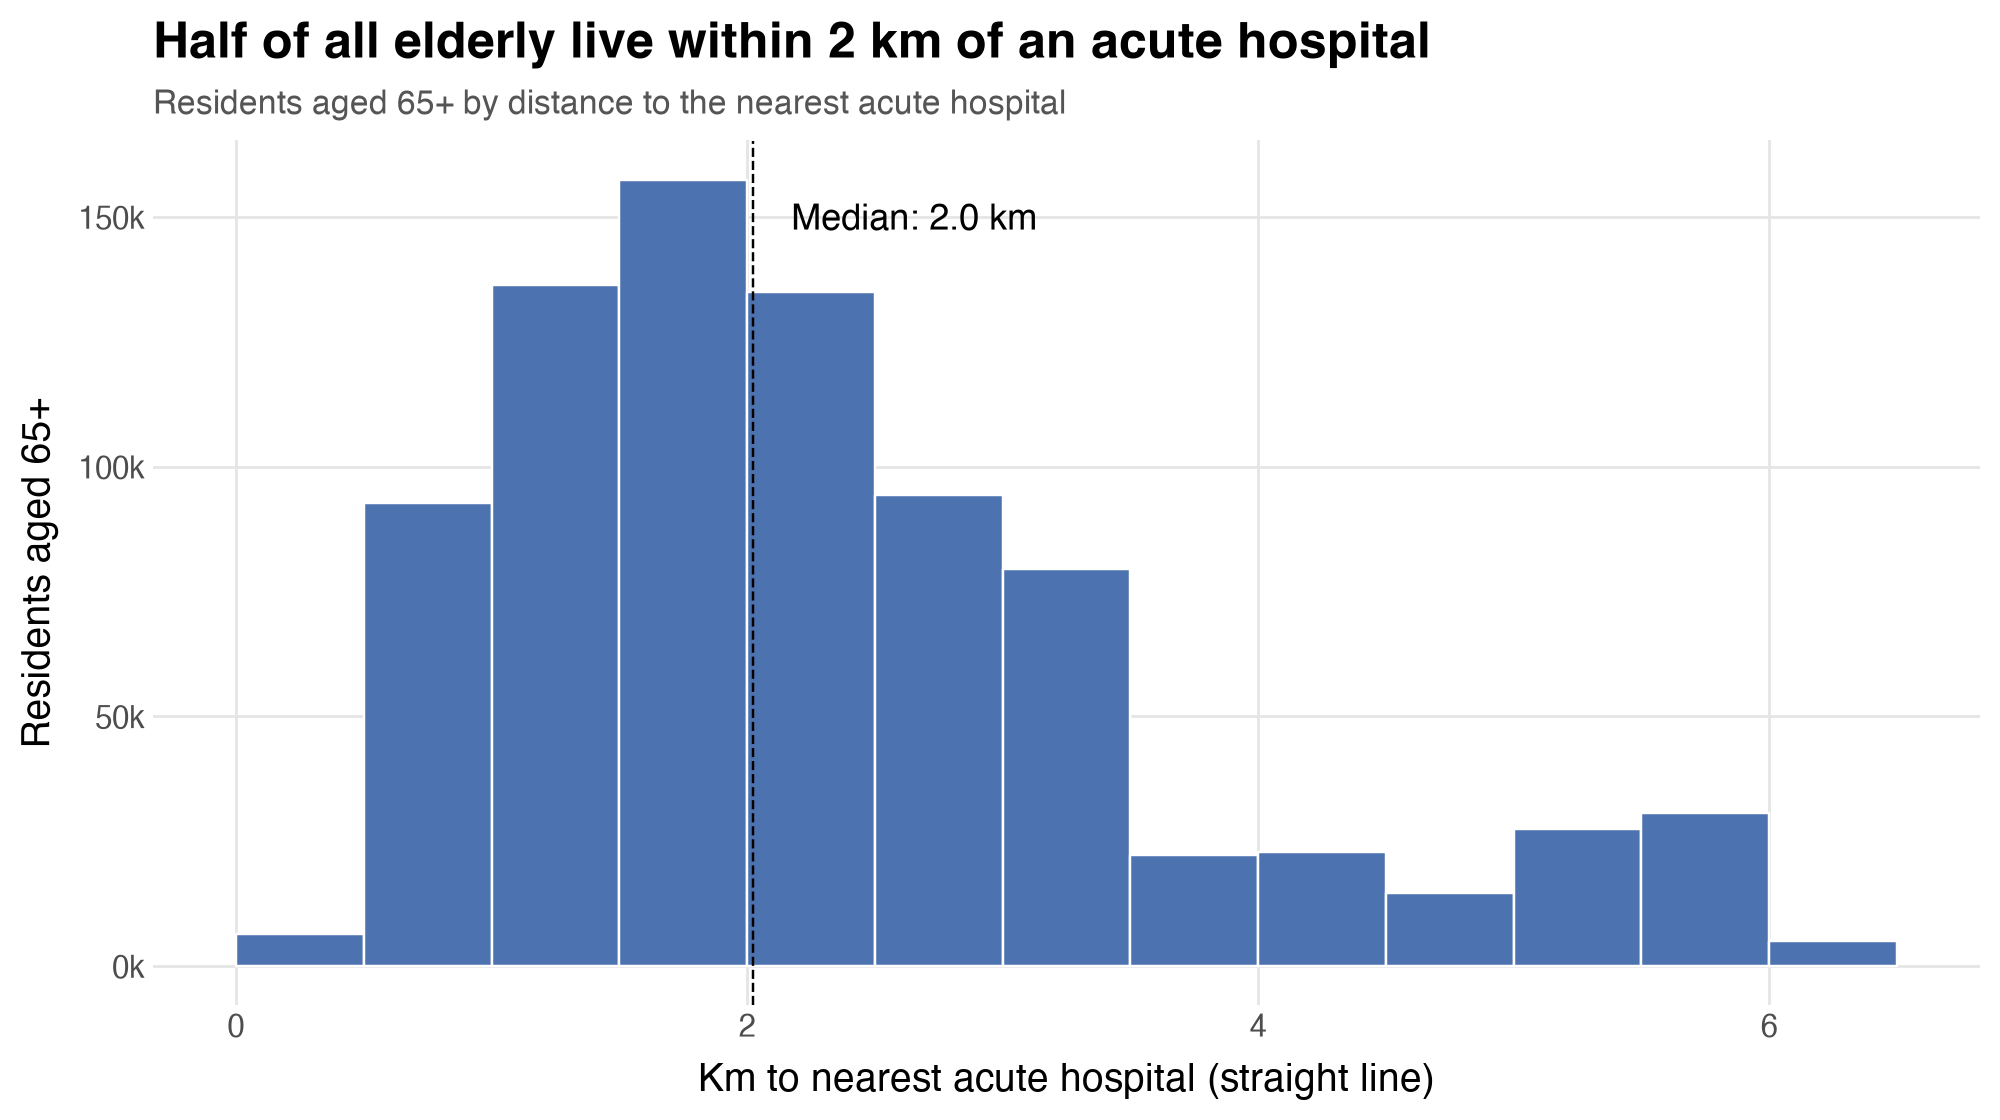

In [5]:
median_km = np.median(np.repeat(df.dist_km_any, df.pop65.astype(int)))
save(
    p9.ggplot(df, p9.aes("dist_km_any", weight="pop65"))
    + p9.geom_histogram(binwidth=0.5, boundary=0, fill="#4C72B0", color="white")
    + p9.geom_vline(xintercept=median_km, linetype="dashed")
    + p9.annotate("text", x=median_km + 0.15, y=150000, label=f"Median: {median_km:.1f} km", ha="left", size=13)
    + p9.scale_y_continuous(labels=lambda v: [f"{x / 1000:.0f}k" for x in v])
    + p9.labs(x="Km to nearest acute hospital (straight line)", y="Residents aged 65+",
              title="Half of all elderly live within 2 km of an acute hospital",
              subtitle="Residents aged 65+ by distance to the nearest acute hospital")
    + SLIDE,
    "04_histogram_elderly_by_distance",
)

## 5. 100% stacked bar: distance bands by region

**Shows:** for each region, how its elderly split across distance bands. `position="fill"` makes every bar
add up to 100%.
**Use it:** to show the regional inequality in one picture: the West bar is mostly dark (far).

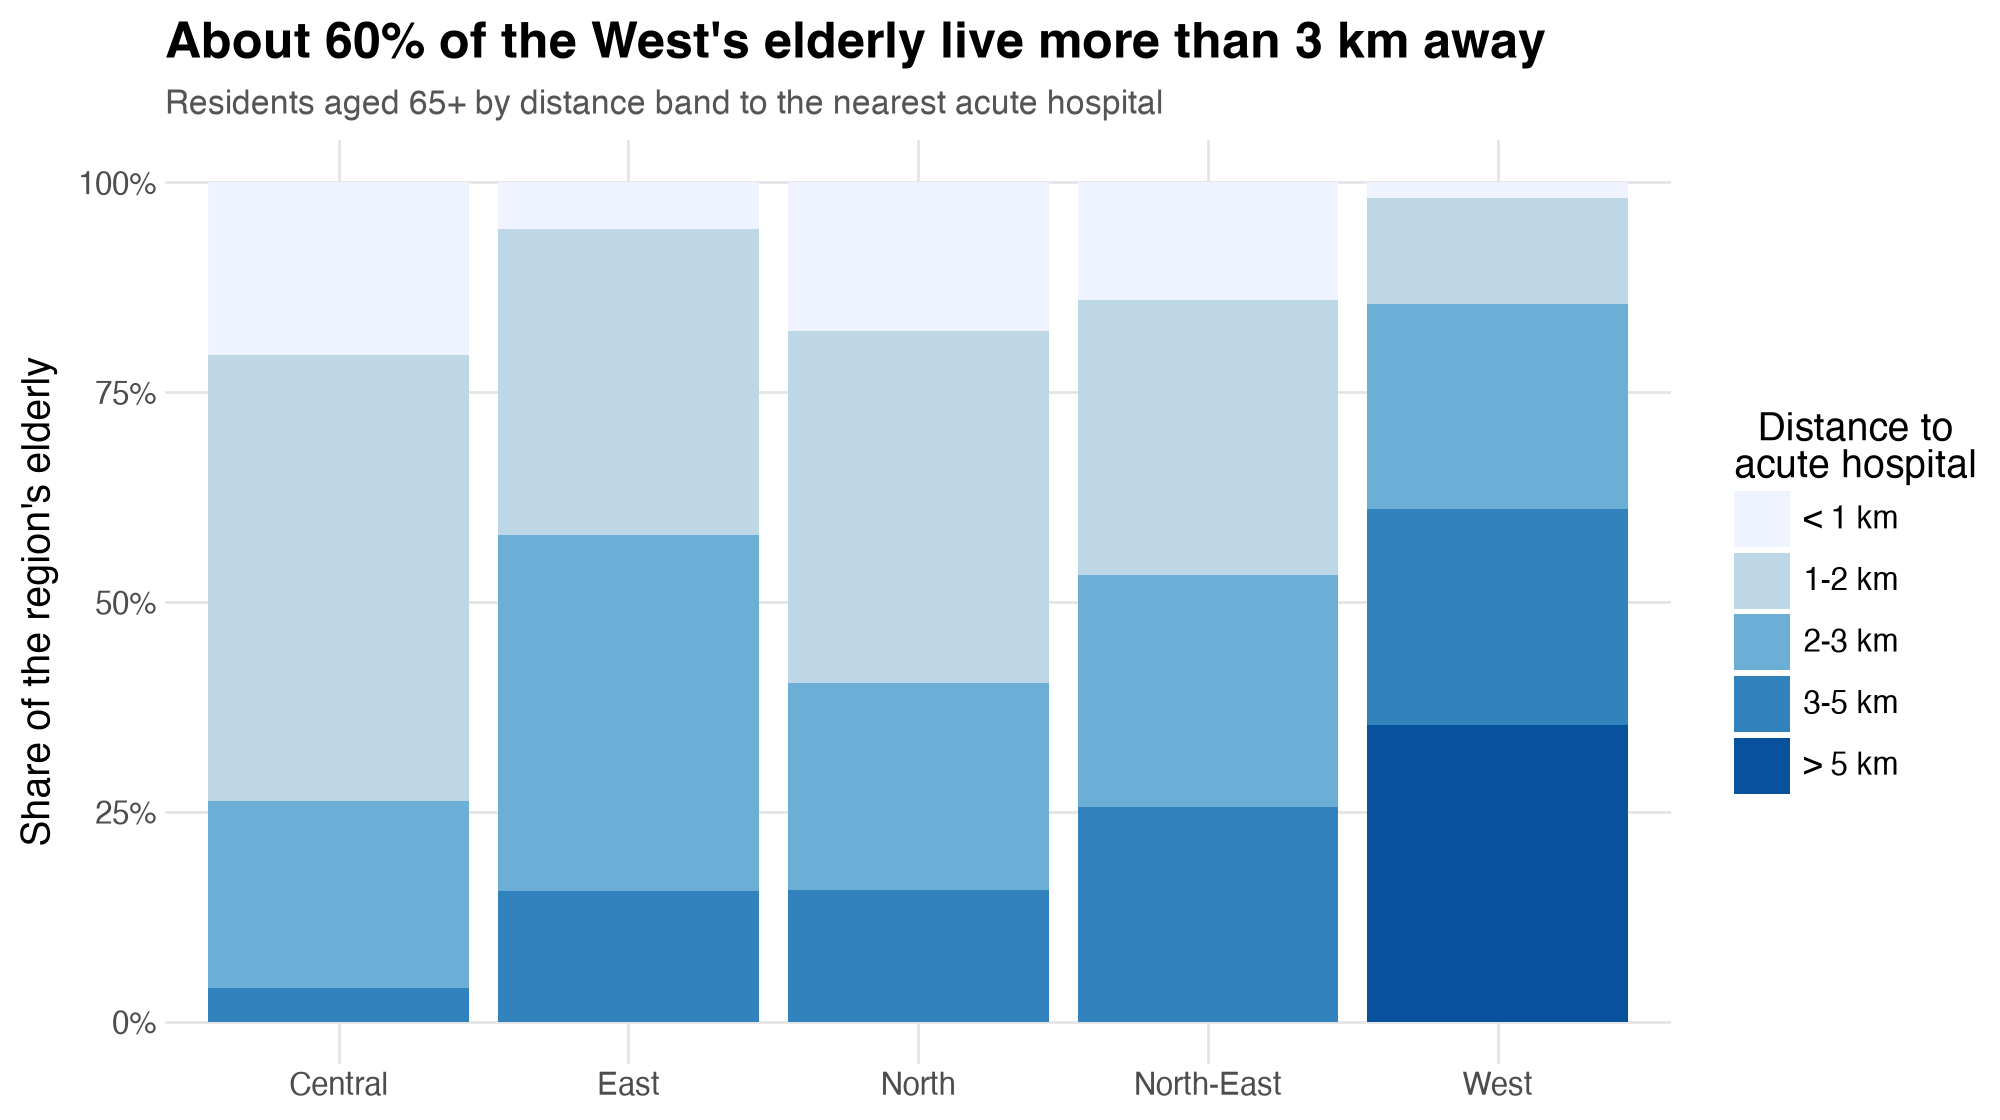

In [6]:
bands = ["< 1 km", "1-2 km", "2-3 km", "3-5 km", "> 5 km"]
df["band"] = pd.cut(df.dist_km_any, [0, 1, 2, 3, 5, np.inf], labels=bands)
band_region = df.groupby(["region", "band"], observed=False).pop65.sum().reset_index()
save(
    p9.ggplot(band_region, p9.aes("region", "pop65", fill="band"))
    + p9.geom_col(position="fill")
    + p9.scale_fill_brewer(type="seq", palette="Blues")
    + p9.scale_y_continuous(labels=lambda v: [f"{x:.0%}" for x in v])
    + p9.labs(x="", y="Share of the region's elderly", fill="Distance to\nacute hospital",
              title="About 60% of the West's elderly live more than 3 km away",
              subtitle="Residents aged 65+ by distance band to the nearest acute hospital")
    + SLIDE,
    "05_stacked_distance_bands_by_region",
)

## 6. Dodged bar: any vs public hospital

**Shows:** elderly-weighted average distance per region, to any acute hospital vs to a public one.
**Use it:** for the financial-limitation point: in the Central region the nearest hospital is often private,
so the affordable option is about 1 km further.

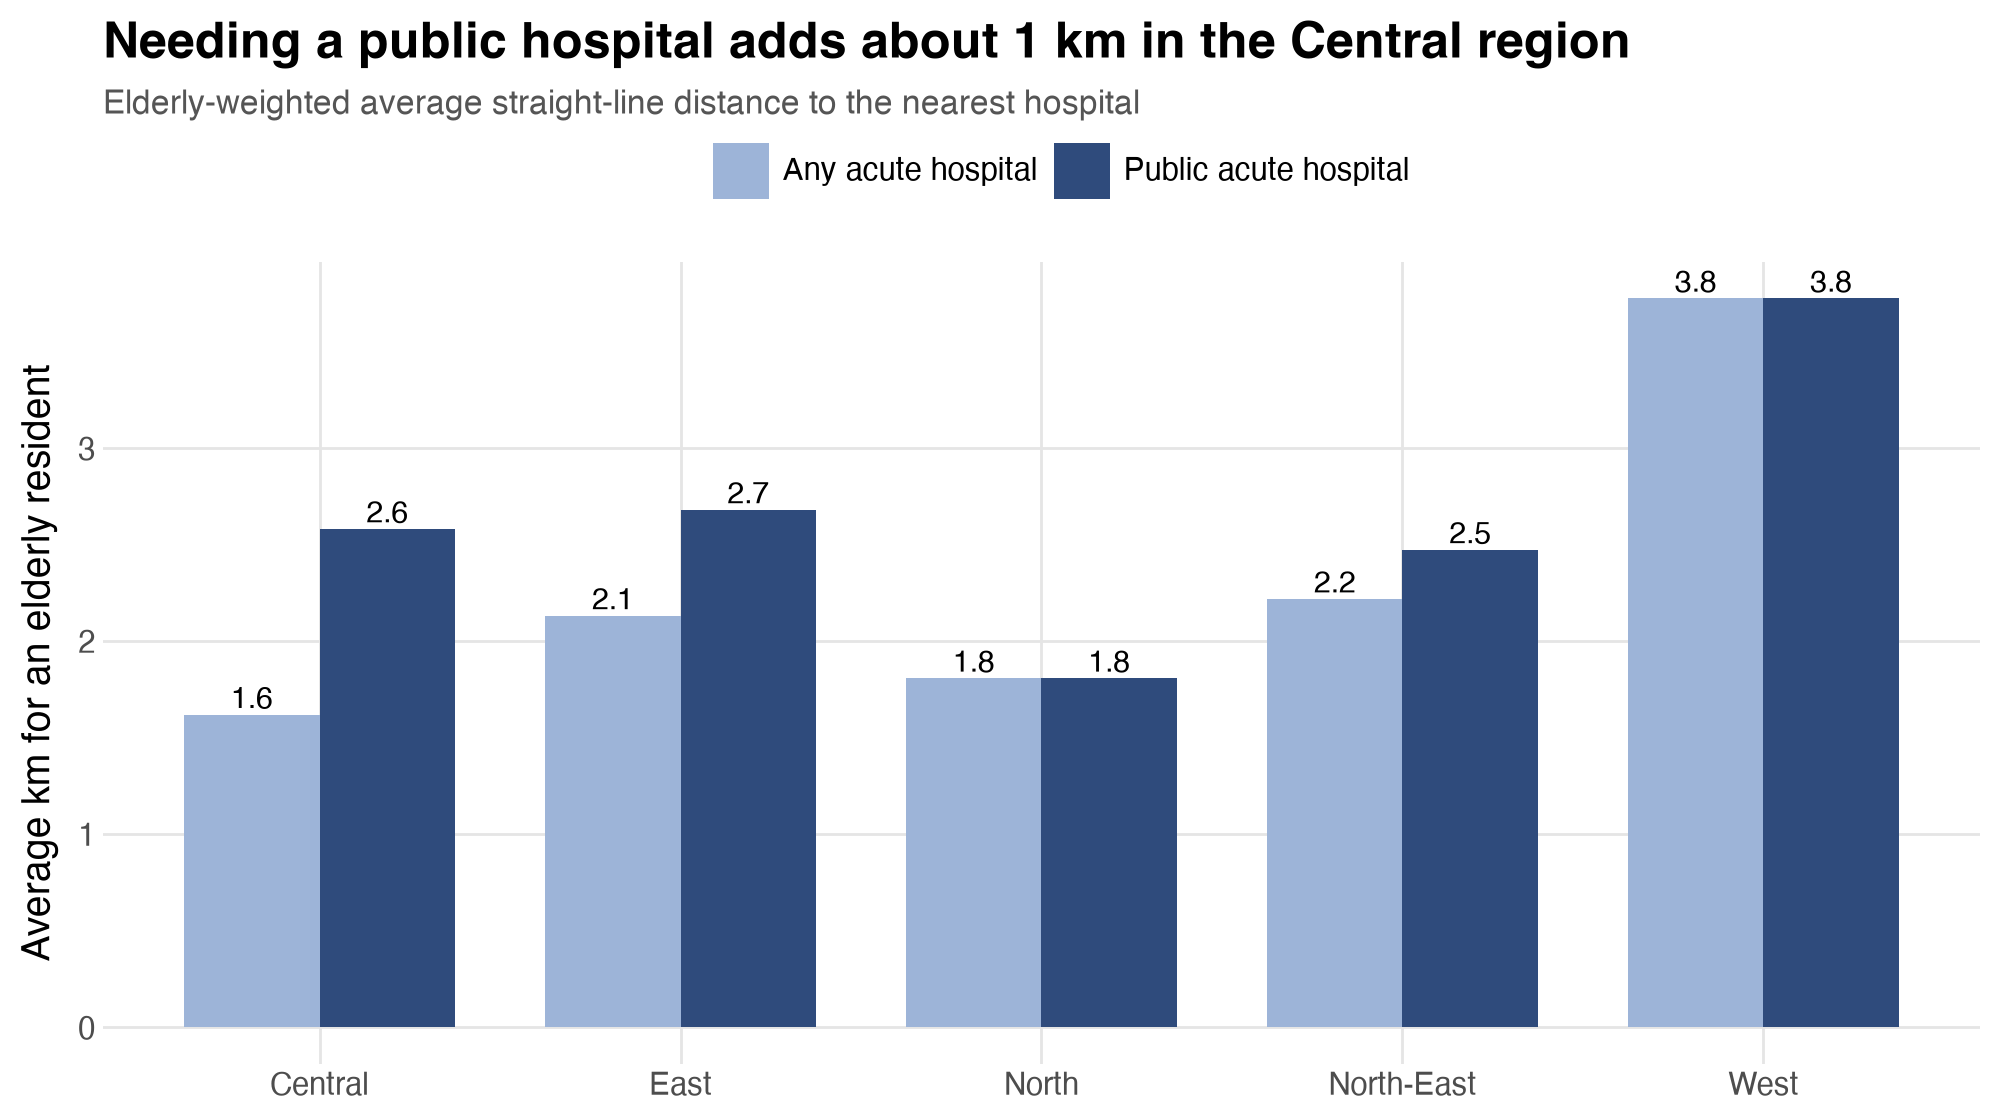

In [7]:
dodge = df.groupby("region", observed=True).apply(lambda g: pd.Series({
    "Any acute hospital": np.average(g.dist_km_any, weights=g.pop65),
    "Public acute hospital": np.average(g.dist_km_public, weights=g.pop65),
})).reset_index().melt(id_vars="region", var_name="hospital", value_name="km")
save(
    p9.ggplot(dodge, p9.aes("region", "km", fill="hospital"))
    + p9.geom_col(position="dodge", width=0.75)
    + p9.geom_text(p9.aes(label="km.round(1)"), position=p9.position_dodge(width=0.75), va="bottom", size=11)
    + p9.scale_fill_manual(["#9DB4D8", "#2F4B7C"])
    + p9.labs(x="", y="Average km for an elderly resident", fill="",
              title="Needing a public hospital adds about 1 km in the Central region",
              subtitle="Elderly-weighted average straight-line distance to the nearest hospital")
    + SLIDE
    + p9.theme(legend_position="top"),
    "06_dodged_any_vs_public",
)

## 7. Boxplot with points: distance by region

**Shows:** the spread of subzone distances in each region; each dot is a subzone, sized by its number of
elderly.
**Use it:** when you want to show both the typical value and the variation (e.g. most Central subzones are
within 2 km, while West subzones range from under 1 km to over 6 km).

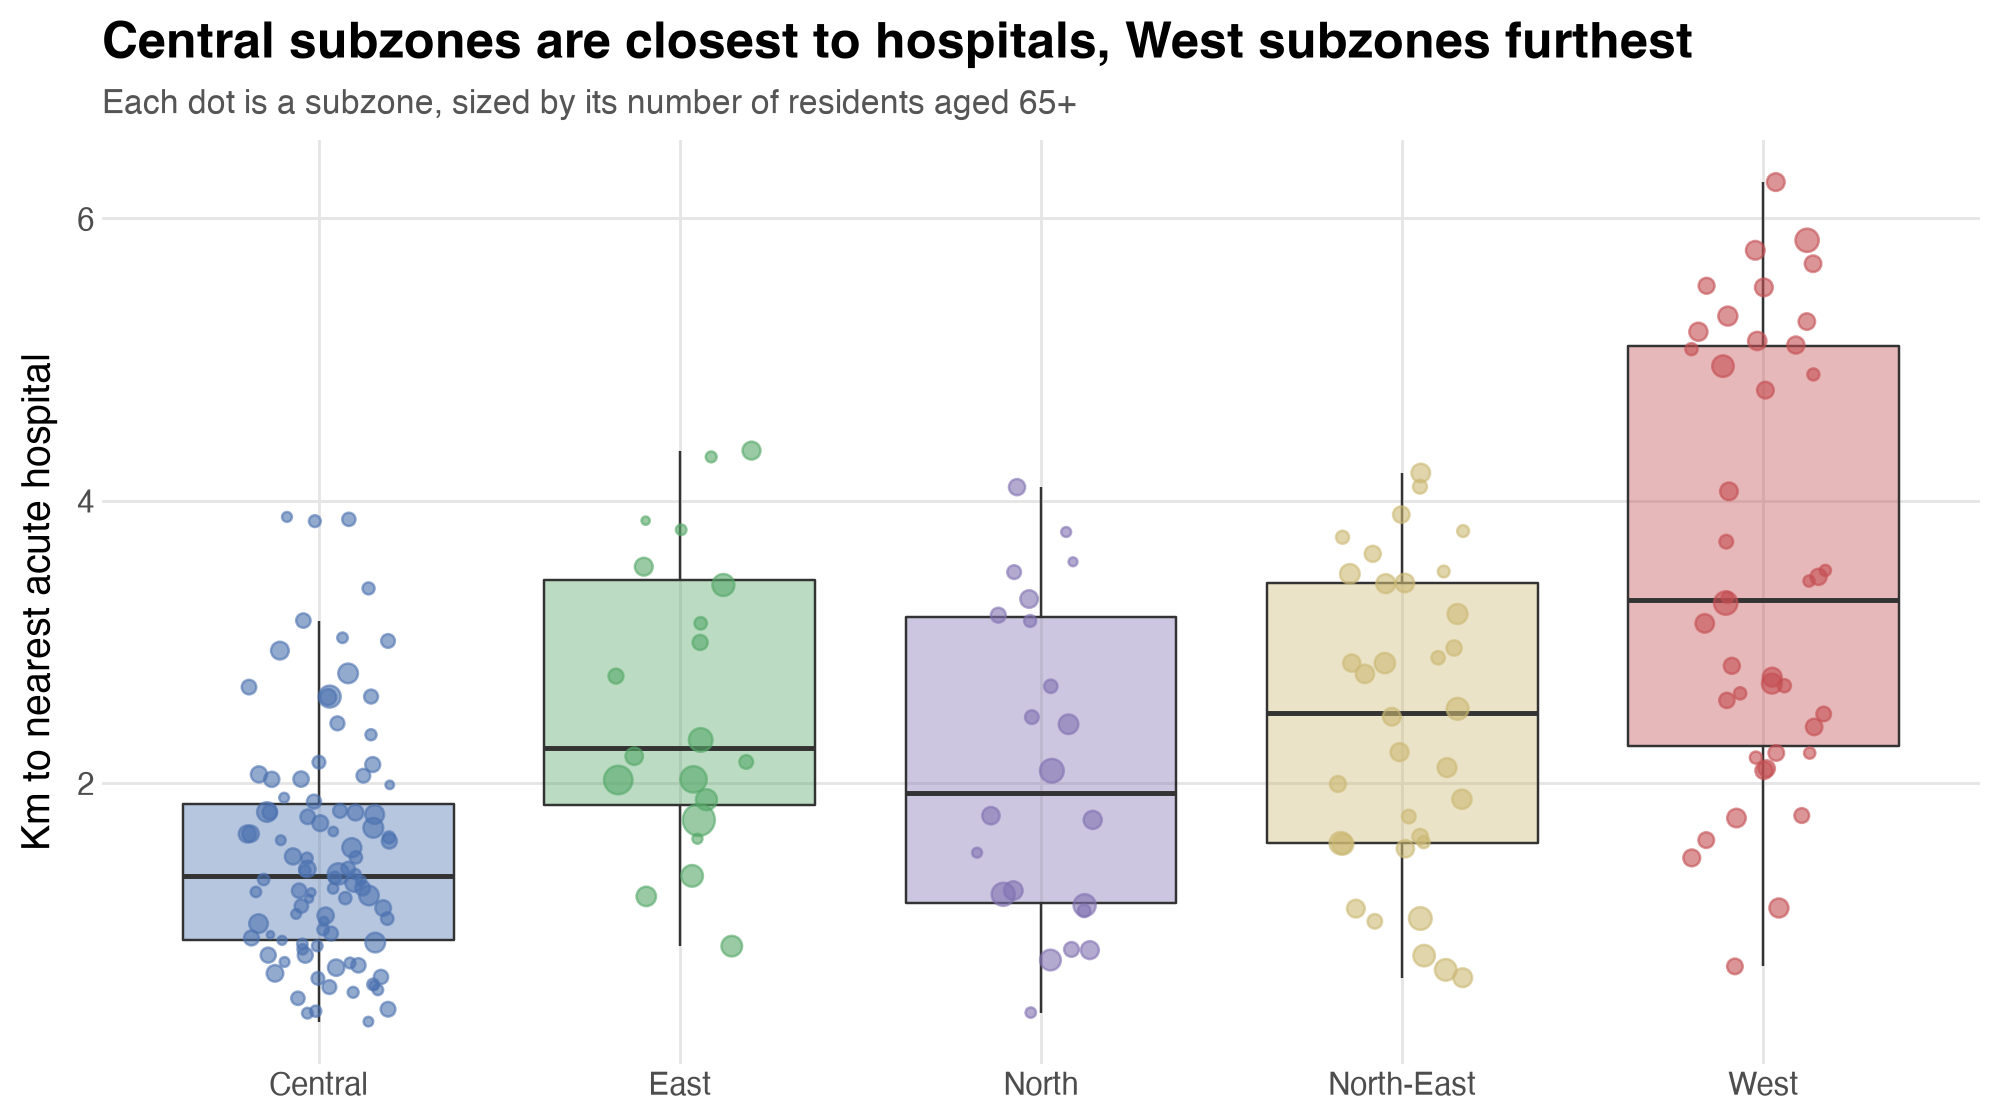

In [8]:
save(
    p9.ggplot(df, p9.aes("region", "dist_km_any", fill="region"))
    + p9.geom_boxplot(outlier_shape="", alpha=0.4, show_legend=False)
    + p9.geom_jitter(p9.aes(size="pop65", color="region"), width=0.2, alpha=0.6, show_legend=False)
    + p9.scale_fill_manual(REGION_COLOURS)
    + p9.scale_color_manual(REGION_COLOURS)
    + p9.labs(x="", y="Km to nearest acute hospital",
              title="Central subzones are closest to hospitals, West subzones furthest",
              subtitle="Each dot is a subzone, sized by its number of residents aged 65+")
    + SLIDE,
    "07_boxplot_distance_by_region",
)

## 8. Scatterplot with trend line

**Shows:** elderly share vs distance for every subzone, with a straight-line fit (`geom_smooth`, week 4).
**Use it:** for the core research question. The flat-to-falling line is the key message: more elderly does
**not** mean further from a hospital.

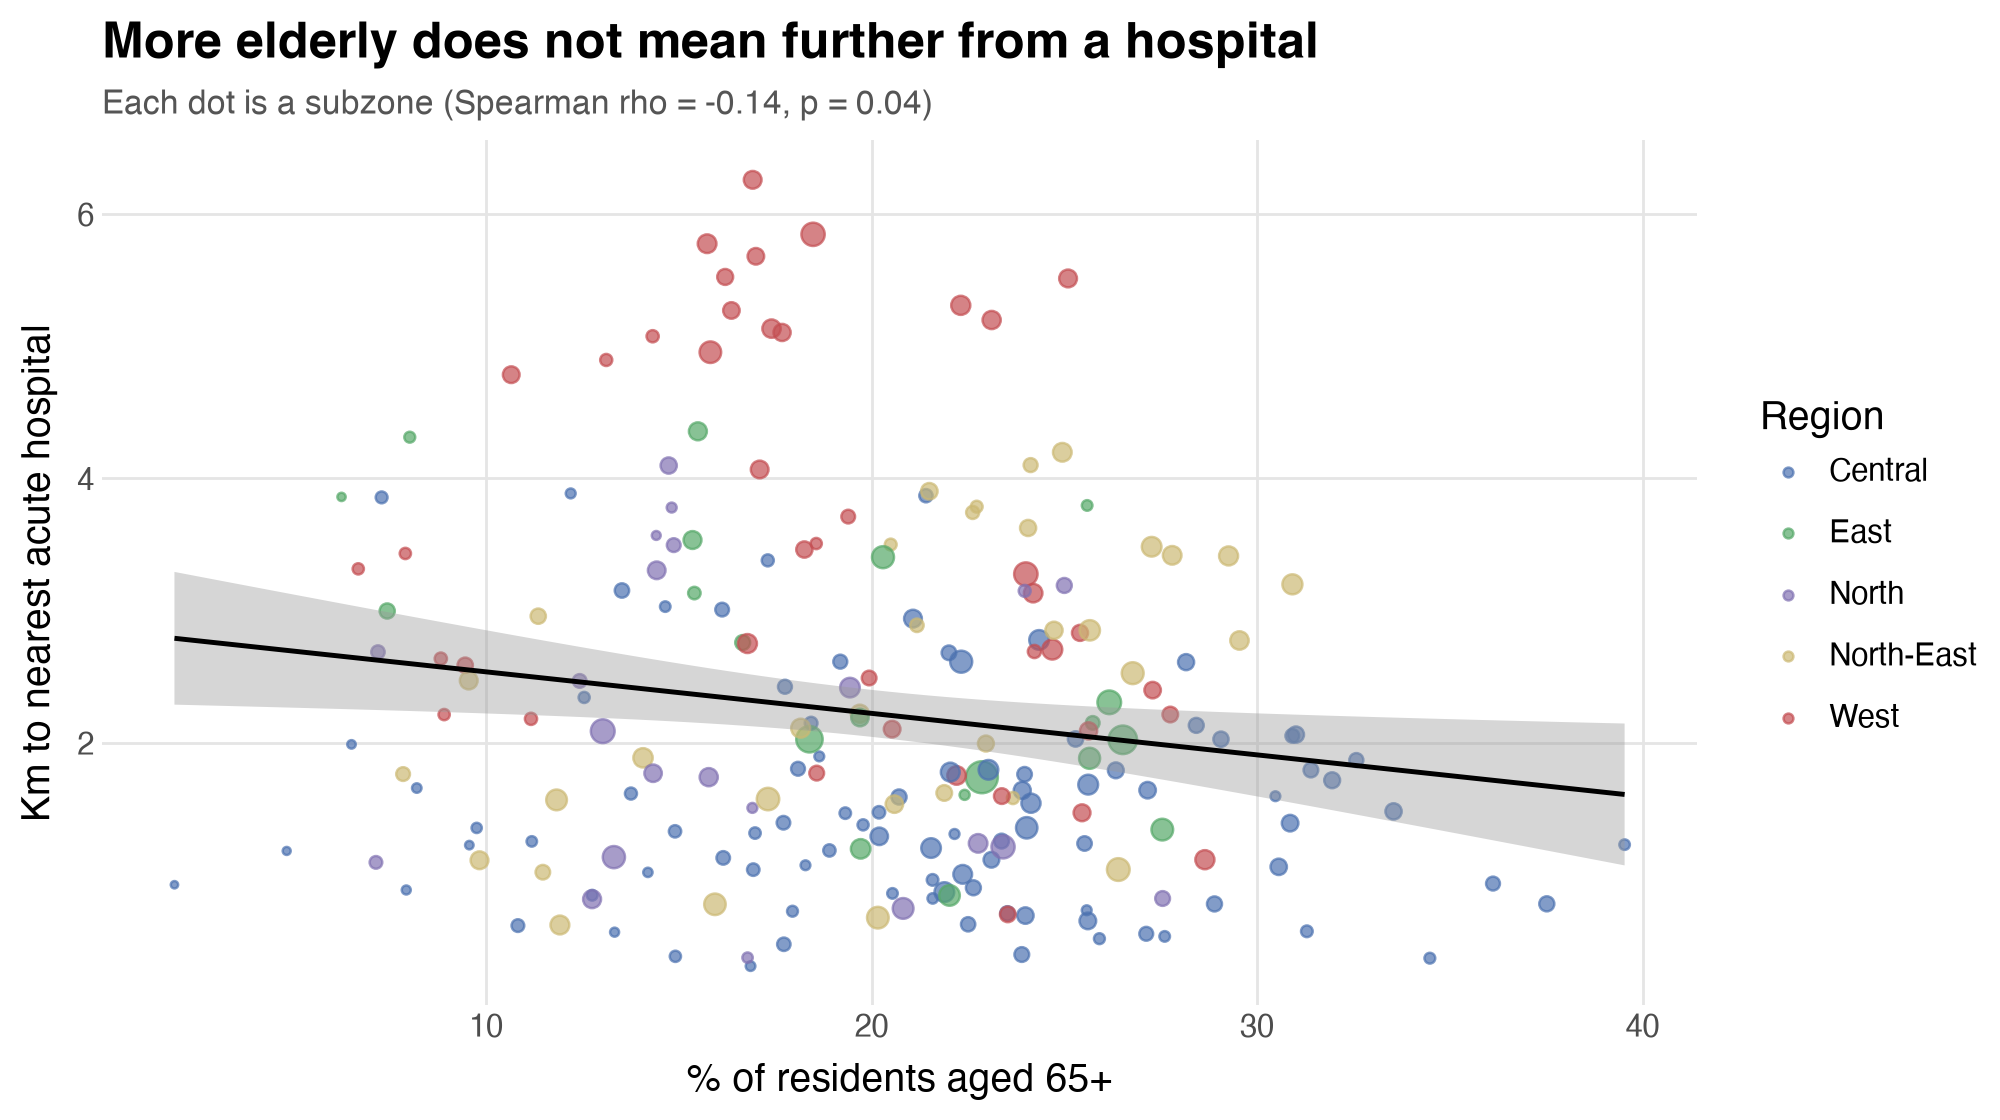

In [9]:
rho, p_rho = stats.spearmanr(df.pct65, df.dist_km_any)
save(
    p9.ggplot(df, p9.aes("pct65", "dist_km_any"))
    + p9.geom_point(p9.aes(color="region", size="pop65"), alpha=0.7)
    + p9.geom_smooth(method="lm", color="black")
    + p9.scale_color_manual(REGION_COLOURS)
    + p9.guides(size=False)
    + p9.labs(x="% of residents aged 65+", y="Km to nearest acute hospital", color="Region",
              title="More elderly does not mean further from a hospital",
              subtitle=f"Each dot is a subzone (Spearman rho = {rho:.2f}, p = {p_rho:.2f})")
    + SLIDE,
    "08_scatter_elderly_vs_distance",
)

## 9. Correlation heatmap

**Shows:** all the Spearman correlations from the analysis as coloured tiles (`geom_tile`), with rho written
in each tile.
**Use it:** as a compact summary slide, or in the appendix. Pale tiles = weak correlation.

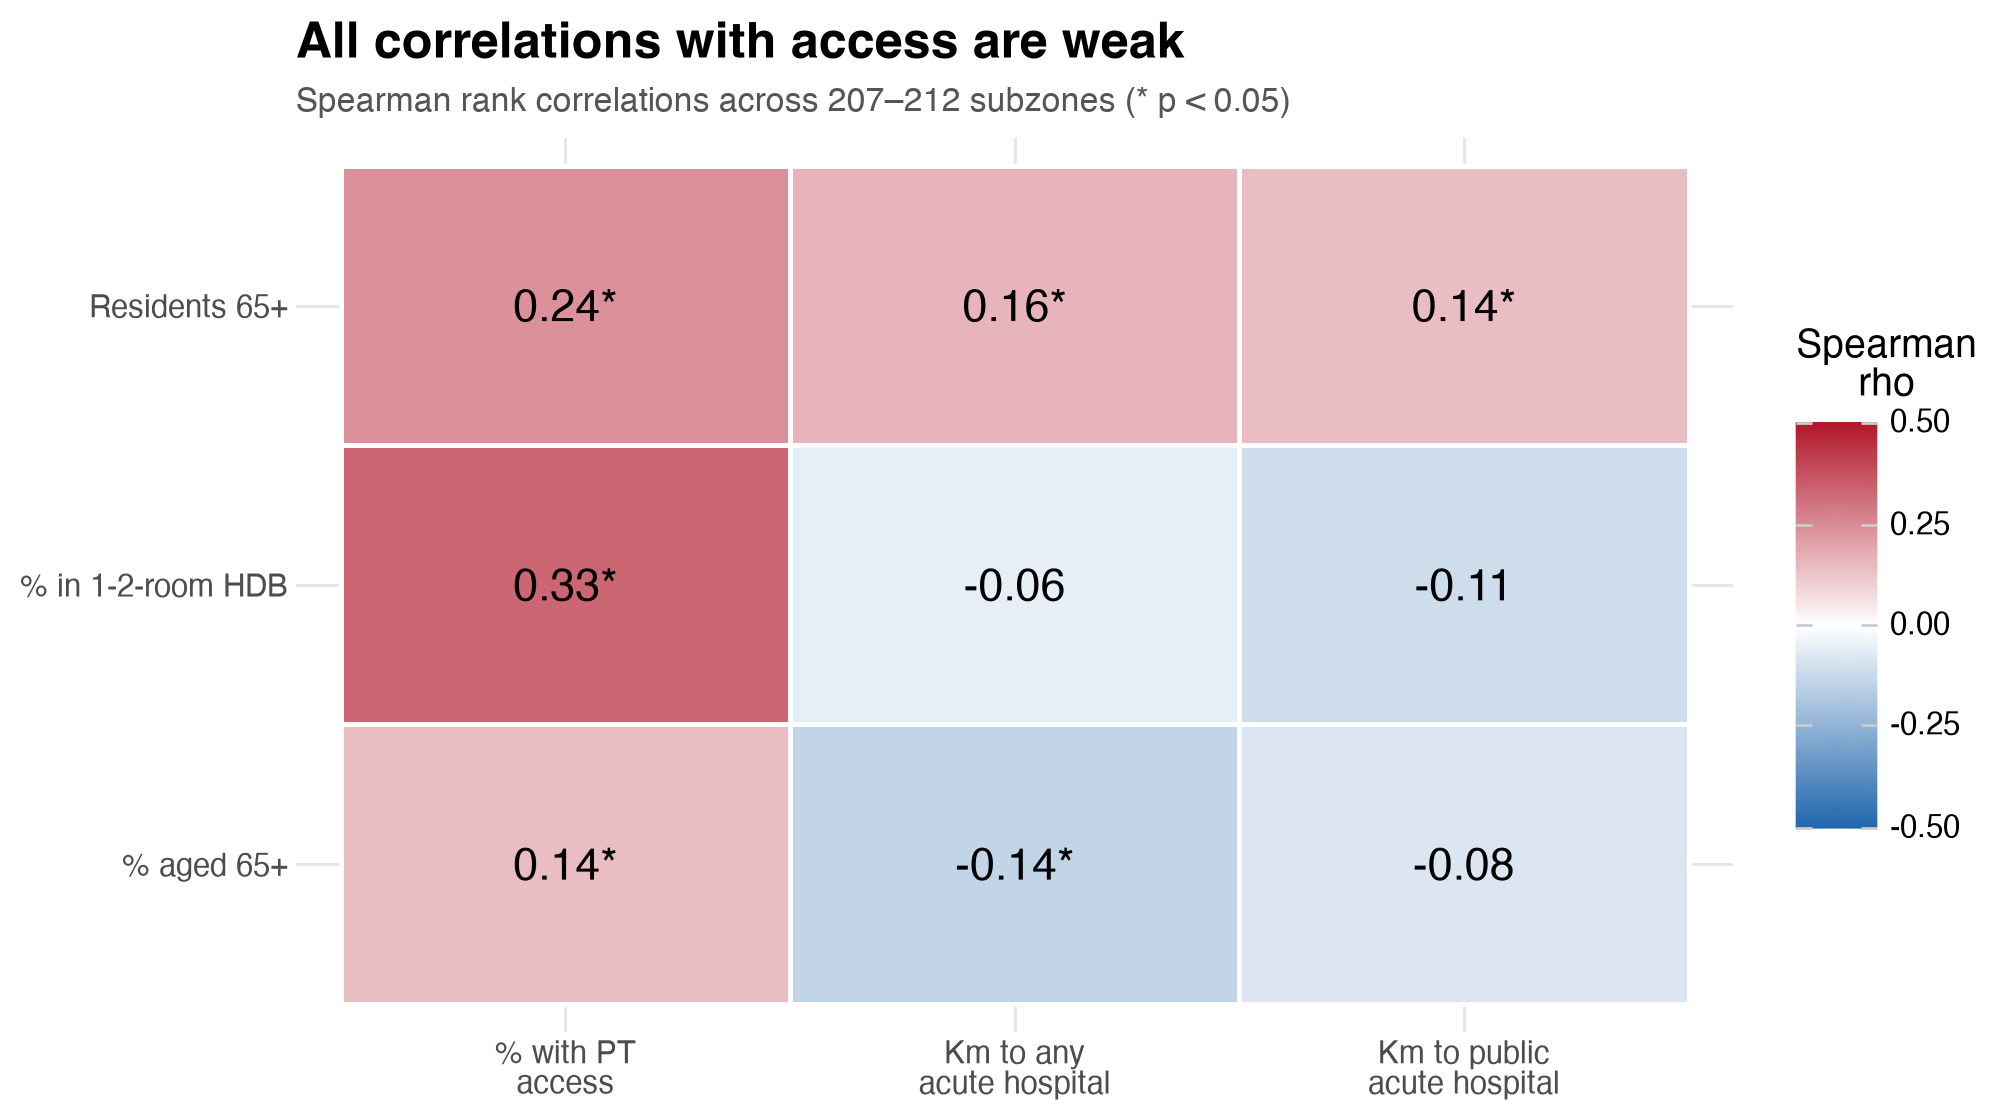

In [10]:
xs = {"pct65": "% aged 65+", "pop65": "Residents 65+", "pct_1_2room": "% in 1-2-room HDB"}
ys = {"dist_km_any": "Km to any\nacute hospital", "dist_km_public": "Km to public\nacute hospital",
      "pct_pt_access": "% with PT\naccess"}
cells = []
for x, xl in xs.items():
    for y, yl in ys.items():
        d = df[[x, y]].dropna()
        r, pv = stats.spearmanr(d[x], d[y])
        cells.append({"x": xl, "y": yl, "rho": r, "label": f"{r:.2f}" + ("*" if pv < 0.05 else "")})
cells = pd.DataFrame(cells)
save(
    p9.ggplot(cells, p9.aes("y", "x", fill="rho"))
    + p9.geom_tile(color="white", size=1)
    + p9.geom_text(p9.aes(label="label"), size=16)
    + p9.scale_fill_gradient2(low="#2166AC", mid="white", high="#B2182B", midpoint=0, limits=(-0.5, 0.5))
    + p9.labs(x="", y="", fill="Spearman\nrho",
              title="All correlations with access are weak",
              subtitle="Spearman rank correlations across 207–212 subzones (* p < 0.05)")
    + SLIDE,
    "09_heatmap_spearman",
)

## 10. Coefficient plot (OLS Model 3)

**Shows:** each coefficient from the week 5-style OLS model as a dot with its 95% confidence interval. If the
line crosses the dashed zero line, the effect is not significant.
**Use it:** on slides instead of a stargazer table, which is too small to read from the back of the room.

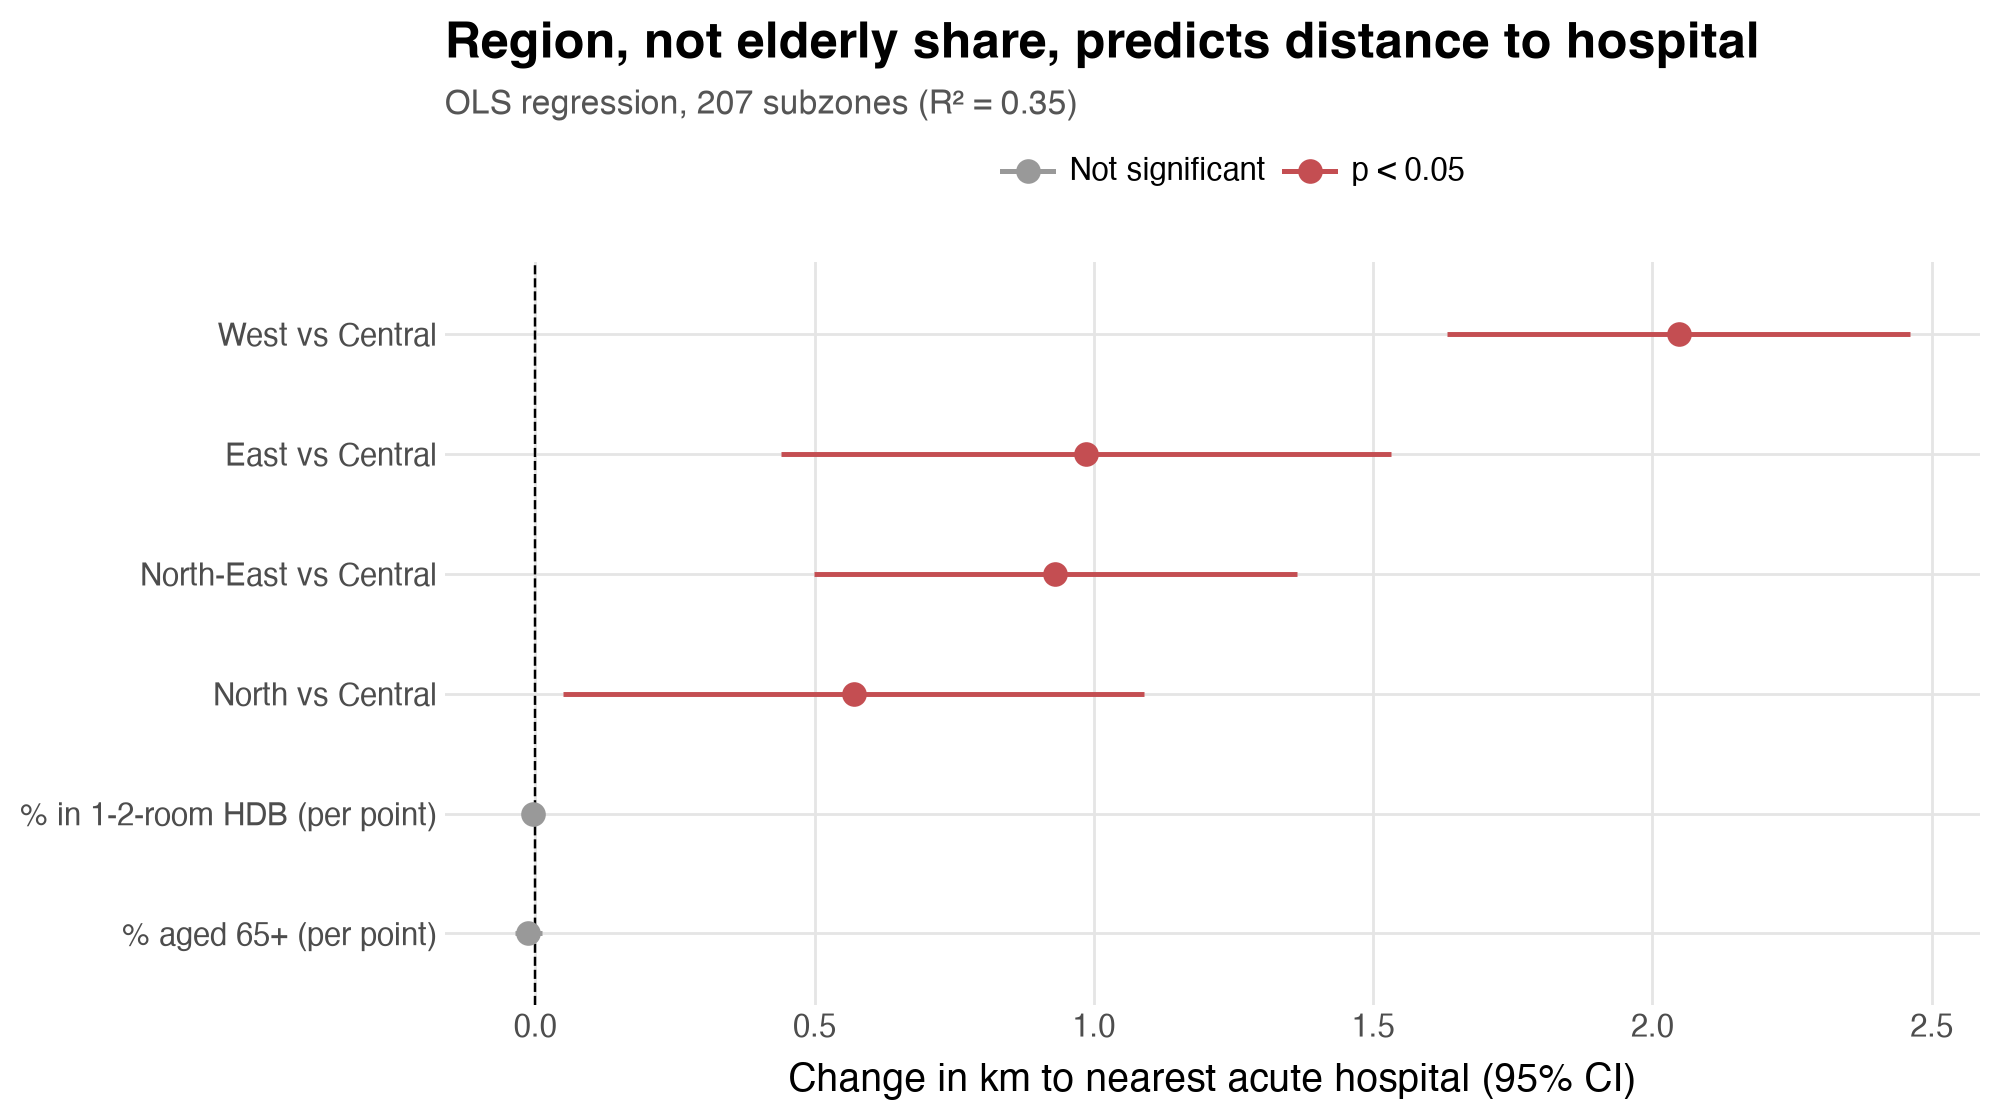

In [11]:
mdf = df.dropna(subset=["pct_1_2room"])
lm3 = smf.ols("dist_km_any ~ pct65 + pct_1_2room + region", data=mdf).fit()
coef = lm3.conf_int().rename(columns={0: "low", 1: "high"}).assign(est=lm3.params).drop("Intercept")
coef["term"] = coef.index.map({
    "pct65": "% aged 65+ (per point)", "pct_1_2room": "% in 1-2-room HDB (per point)",
    "region[T.East]": "East vs Central", "region[T.North]": "North vs Central",
    "region[T.North-East]": "North-East vs Central", "region[T.West]": "West vs Central",
})
coef["significant"] = np.where((coef.low > 0) | (coef.high < 0), "p < 0.05", "Not significant")
save(
    p9.ggplot(coef, p9.aes("reorder(term, est)", "est", color="significant"))
    + p9.geom_hline(yintercept=0, linetype="dashed")
    + p9.geom_pointrange(p9.aes(ymin="low", ymax="high"), size=1)
    + p9.coord_flip()
    + p9.scale_color_manual({"p < 0.05": "#C44E52", "Not significant": "#999999"})
    + p9.labs(x="", y="Change in km to nearest acute hospital (95% CI)", color="",
              title="Region, not elderly share, predicts distance to hospital",
              subtitle=f"OLS regression, 207 subzones (R² = {lm3.rsquared:.2f})")
    + SLIDE
    + p9.theme(legend_position="top"),
    "10_coefficient_plot_ols",
)

## 11. Predicted probability of being far, by region (logit)

**Shows:** from the week 6-style logit model, the predicted chance that a subzone is more than 3 km from an
acute hospital in each region, holding elderly share and low-income share at their averages. `predictions`
and `datagrid` come from `marginaleffects`, the package used for marginal effects in week 6.
**Use it:** to turn the logit into one easy sentence ("a West subzone has about a 1-in-2 chance of being far").

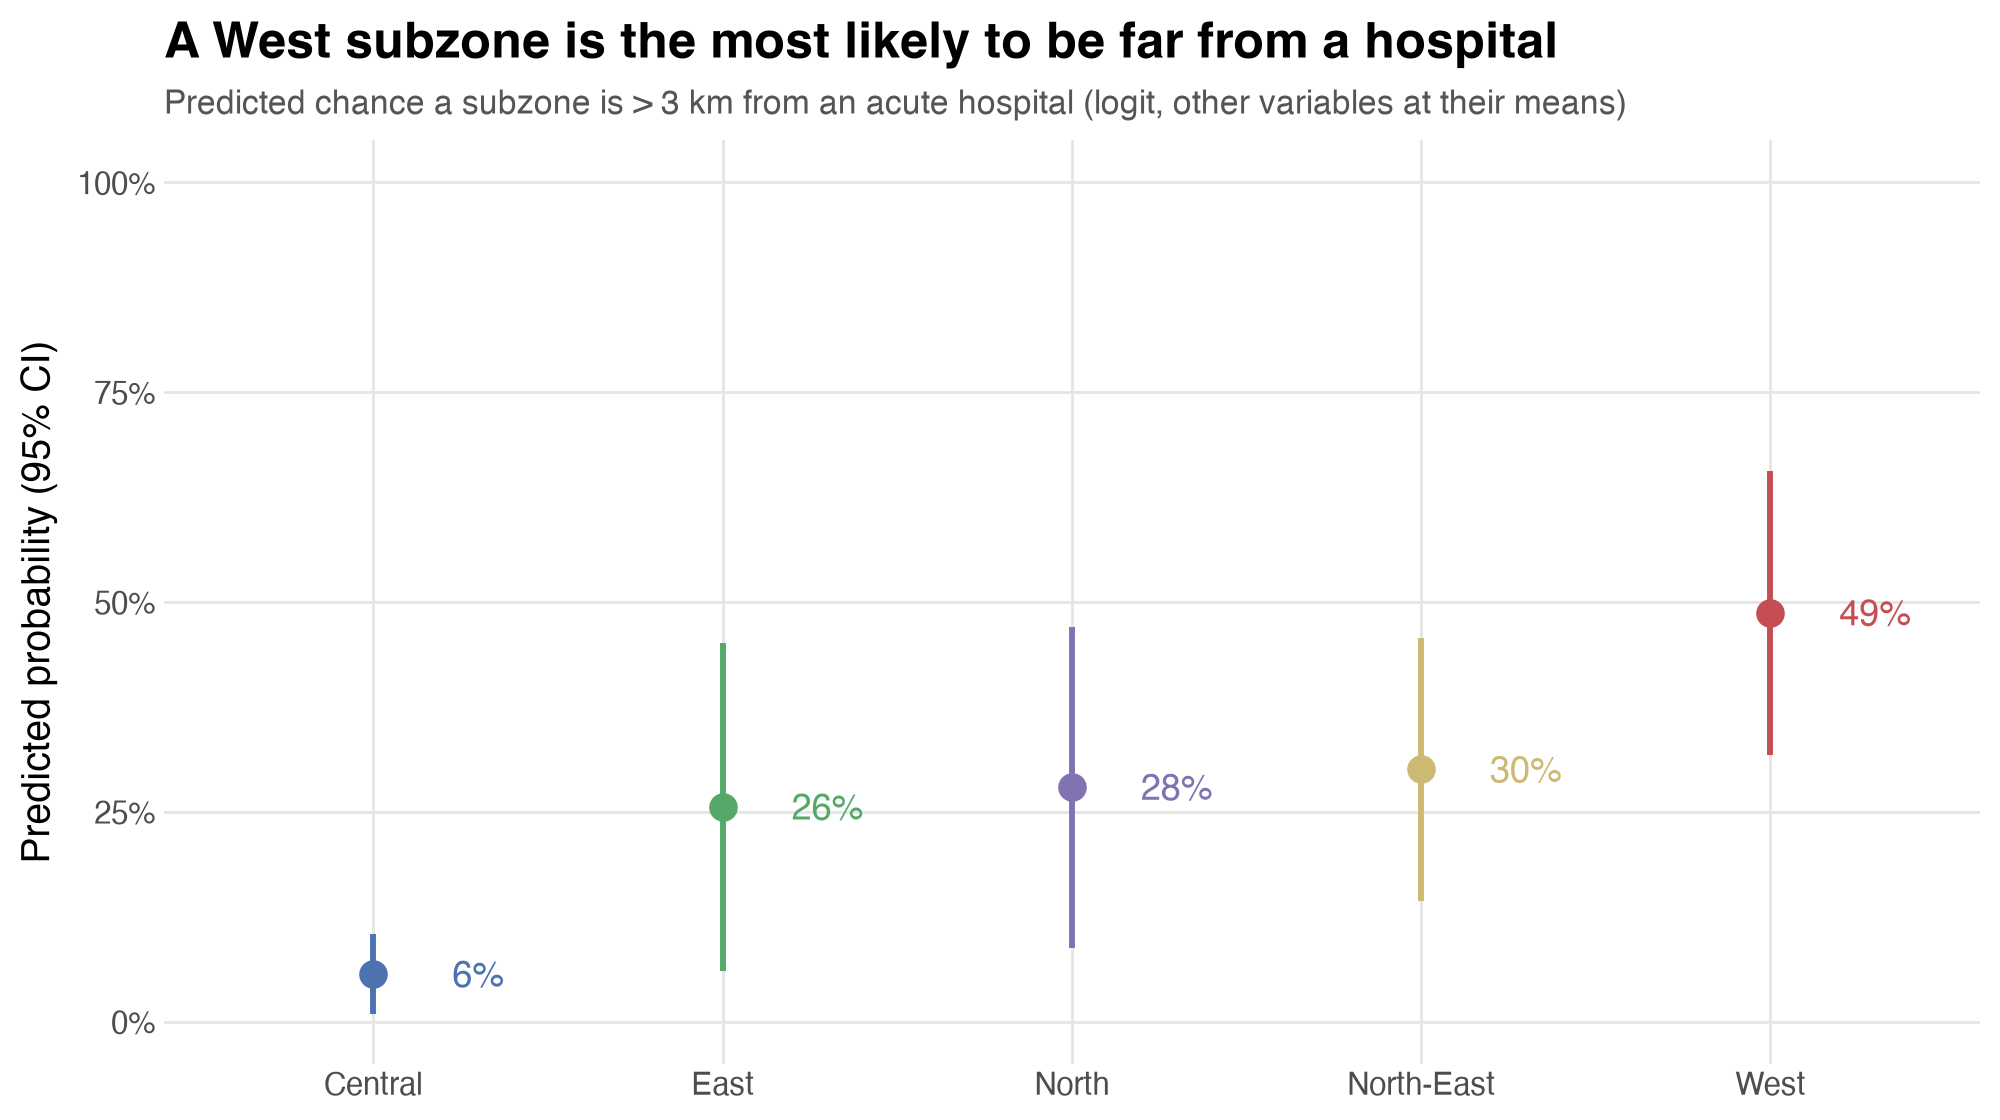

In [12]:
mdf = mdf.assign(far=(mdf.dist_km_any > 3).astype(int))
lg3 = smf.logit("far ~ pct65 + pct_1_2room + region", data=mdf).fit(disp=0)
pred = predictions(lg3, newdata=datagrid(model=lg3, region=REGIONS)).to_pandas()
pred["region"] = pd.Categorical(pred.region, categories=REGIONS)
save(
    p9.ggplot(pred, p9.aes("region", "estimate", color="region"))
    + p9.geom_pointrange(p9.aes(ymin="conf_low", ymax="conf_high"), size=1.2, show_legend=False)
    + p9.geom_text(p9.aes(label="(estimate * 100).round(0).astype(int).astype(str) + '%'"),
                   nudge_x=0.3, size=13, show_legend=False)
    + p9.scale_color_manual(REGION_COLOURS)
    + p9.scale_y_continuous(labels=lambda v: [f"{x:.0%}" for x in v], limits=(0, 1))
    + p9.labs(x="", y="Predicted probability (95% CI)",
              title="A West subzone is the most likely to be far from a hospital",
              subtitle="Predicted chance a subzone is > 3 km from an acute hospital (logit, other variables at their means)")
    + SLIDE,
    "11_predicted_probability_logit",
)

## 12. Lollipop chart: priority subzones

**Shows:** the 10 subzones with the most elderly living more than 4 km from an acute hospital
(`geom_segment` + `geom_point`).
**Use it:** for the policy / conclusion slide: concrete place names make the finding real.

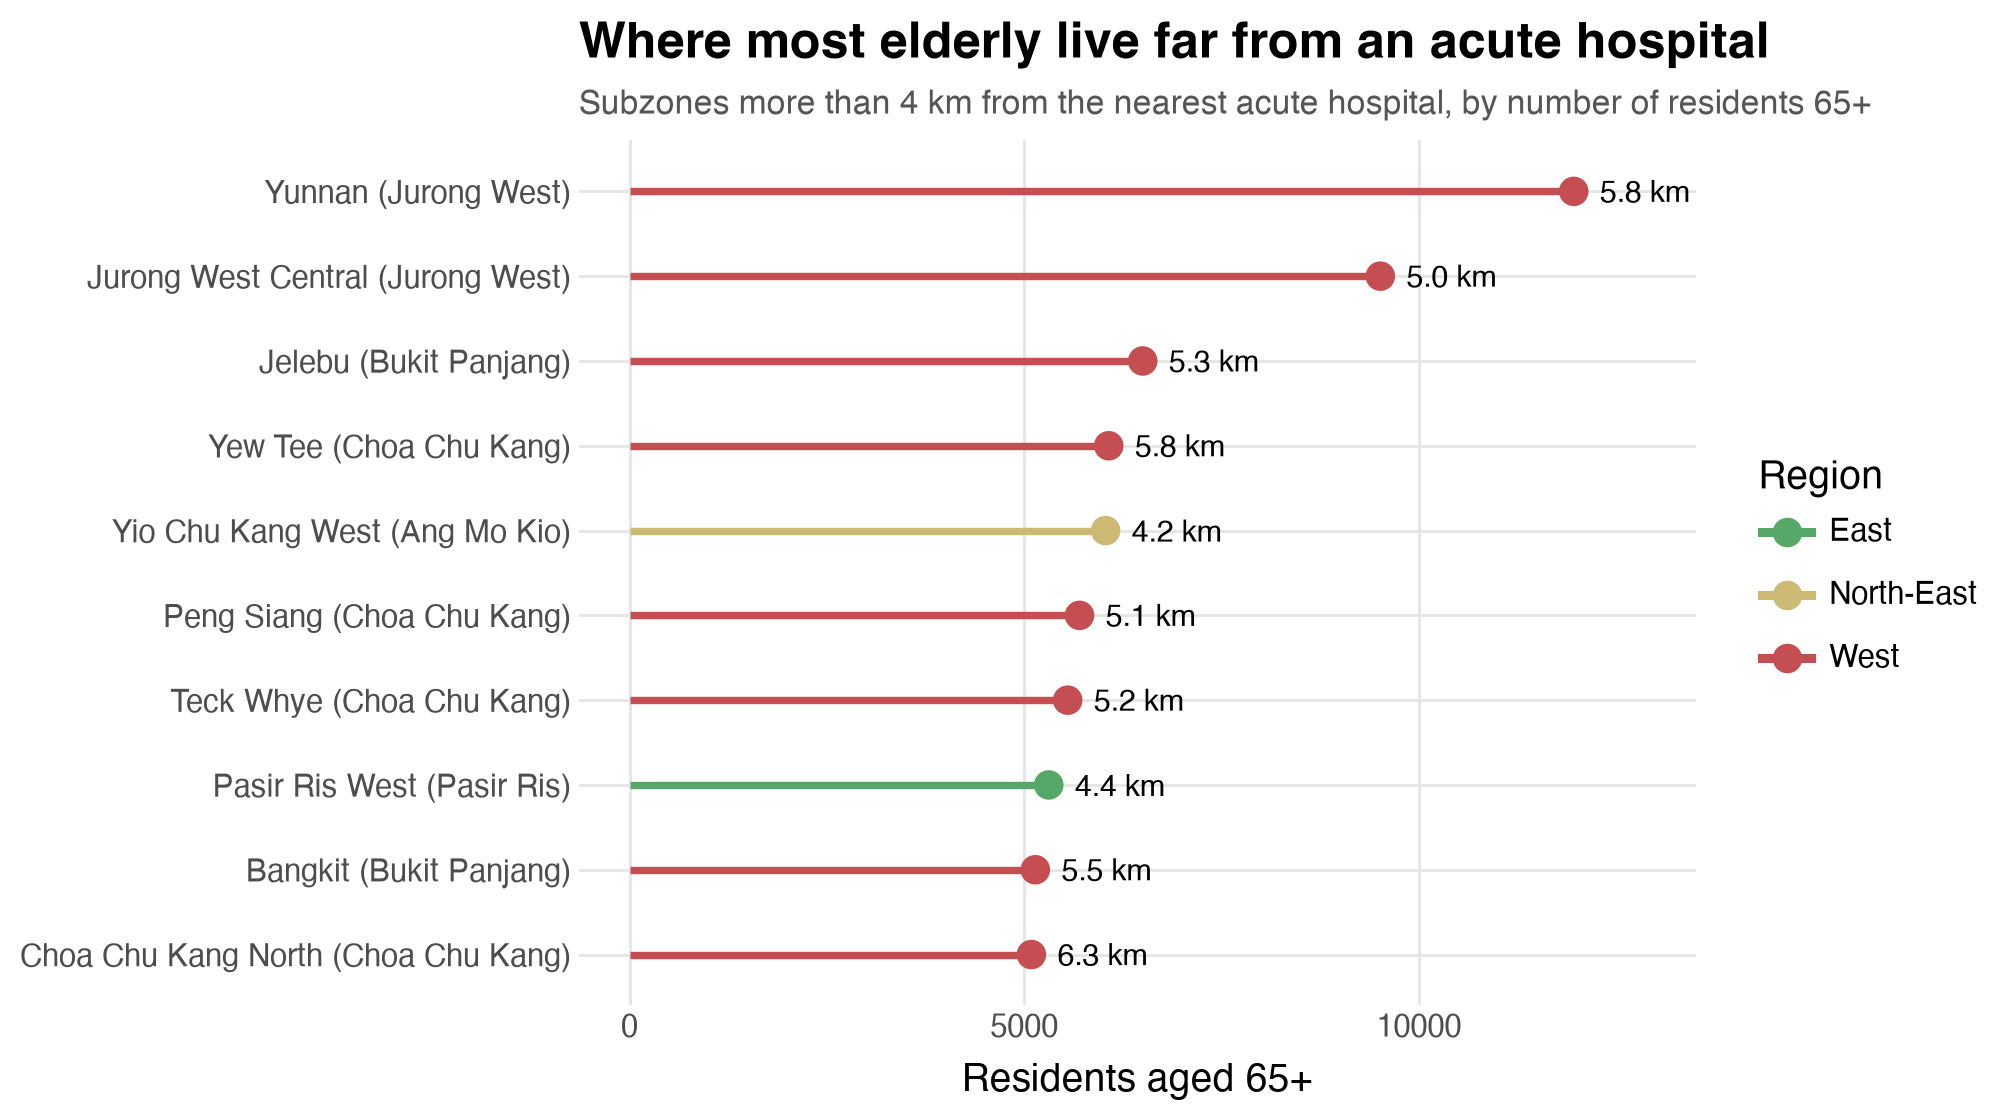

In [13]:
top = df[df.dist_km_any > 4].nlargest(10, "pop65").copy()
top["label"] = top.subzone + " (" + top.planning_area + ")"
top["region"] = top.region.astype(str)  # show only the regions that appear
save(
    p9.ggplot(top, p9.aes("reorder(label, pop65)", "pop65", color="region"))
    + p9.geom_segment(p9.aes(xend="reorder(label, pop65)", y=0, yend="pop65"), size=1.5)
    + p9.geom_point(size=5)
    + p9.geom_text(p9.aes(label="dist_km_any.round(1).astype(str) + ' km'"), nudge_y=900, size=11, color="black")
    + p9.coord_flip()
    + p9.scale_color_manual(REGION_COLOURS)
    + p9.labs(x="", y="Residents aged 65+", color="Region",
              title="Where most elderly live far from an acute hospital",
              subtitle="Subzones more than 4 km from the nearest acute hospital, by number of residents 65+")
    + SLIDE,
    "12_lollipop_priority_subzones",
)